# Vorlesung 2 – Datenvorbereitung
### Erweiterte Fassung · kommentierte Beispiele, Vergleiche und Visualisierungen

Diese Fassung entwickelt das ursprüngliche Skript Schritt für Schritt weiter – **ohne zusätzliche Themen**. Alle ursprünglichen Inhalte bleiben erhalten: CSV einlesen, Daten-/Spaltentypen, Bereinigung und Duplikate, Datumsmerkmale, fehlende Werte und Missing-Indikatoren, Imputation, One-Hot-Encoding, drei Skalierungsarten, Ausreißer-Kappen, Train/Test-Aufteilung, `Pipeline` / `ColumnTransformer`, Diagnostik und CSV-Export.

**Ausführung:** Die Zellen von oben nach unten starten (*Kernel → Restart & Run All*). Wenn im Arbeitsverzeichnis eine `data.csv` liegt, wird diese wie im Original verwendet. Ohne Datei wird ein **größerer, reproduzierbarer Beispieldatensatz** zum gleichen Wohnungsbeispiel erzeugt; er enthält bewusst fehlende Werte, uneinheitliche Kategorien, Ausreißer und Duplikate. Die Ausgabe-Dateien `prepared_train.csv` und `prepared_test.csv` entstehen erst in der letzten Zelle.

**Merksatz:** Alle Schritte, die Parameter aus Daten **lernen** (Median, häufigste Kategorie, Grenzen zum Kappen, Skalierung, One-Hot-Kategorien), werden ausschließlich am **Trainingssatz** angepasst.

## 0 · Vorbereitung und reproduzierbares Beispiel

Das ursprüngliche Skript lädt `data.csv` und verwendet andernfalls ein kleines CSV-Beispiel. Hier bleibt diese Logik bestehen. Für aussagekräftige Diagramme erzeugen wir im Fallback mehr Beobachtungen zu denselben Variablen: `date`, `city`, `rooms`, `area_m2`, `price` und `has_elevator`. Für externe CSV-Dateien sollte das Spaltenschema entsprechend vergleichbar sein.

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import FancyBboxPatch
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

# Konfiguration – anpassbar wie im Original
CSV_PATH = 'data.csv'
SCALE_KIND = 'zscore'            # 'zscore' | 'minmax' | 'robust'
RANDOM_STATE = 42
NA_TOKENS = ['', ' ', 'NA', 'N/A', 'n/a', 'NaN', 'nan', 'NULL', 'null', '?', '-', '--']

# Einheitlicher Plot-Stil
BLUE, TEAL, ORANGE, RED, PURPLE = '#2563eb', '#0d9488', '#ea580c', '#dc2626', '#7c3aed'
PALE = '#e8eef8'
plt.rcParams.update({
    'figure.figsize': (10, 4.2), 'figure.dpi': 105,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': .17,
    'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'font.size': 10,
})
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 130)
print('Bibliotheken geladen. Skalierungswahl:', SCALE_KIND)

Bibliotheken geladen. Skalierungswahl: zscore


In [2]:
def build_example_csv():
    """Größerer CSV-Fallback mit denselben Feldern wie im Original (reproduzierbar)."""
    example_rows = [
        ['2025-01-03', 'Berlin', 2, 45, 245000, 'yes'],
        ['2025-02-10', 'berlin', 'NA', 60, 315000, 'no'],
        ['2024-12-15', 'München', 1, 34, '?', 'yes'],
        ['2025-01-20', 'Hamburg', 3, 85, 520000, 'yes'],
        ['2025-03-02', 'München', 2, ' ', 480000, 'no'],
        ['2025-03-05', 'Berlin', 2, 55, 310000, 'unknown'],
    ]
    rng = np.random.default_rng(2025)
    for i in range(84):
        city = str(rng.choice(['Berlin', 'berlin', 'Hamburg', 'hamburg', 'München', 'münchen']))
        rooms = int(rng.choice([1, 2, 3, 4], p=[.17, .40, .31, .12]))
        area = int(np.clip(rng.normal(34 + rooms * 16, 12), 24, 145))
        city_add = 68000 if 'münchen' in city.lower() else (25000 if 'hamburg' in city.lower() else 0)
        price = int(round((85000 + area * 4400 + rooms * 11000 + city_add + rng.normal(0, 26000)) / 1000) * 1000)
        date = (pd.Timestamp('2024-11-01') + pd.Timedelta(days=int(rng.integers(0, 165)))).strftime('%Y-%m-%d')
        elevator = str(rng.choice(['yes', 'no', 'unknown'], p=[.56, .35, .09]))
        row = [date, city, rooms, area, price, elevator]
        # Typische Probleme absichtlich einbauen – keine zusätzlichen Variablen.
        if i in [3, 17, 28, 52, 75]: row[2] = 'NA'            # rooms fehlt
        if i in [6, 21, 47, 69]: row[3] = '?'                # area fehlt
        if i in [8, 39, 64]: row[4] = 'N/A'                  # price fehlt
        if i in [13, 43, 73]: row[1] = ' '                  # city fehlt
        if i in [10, 35, 57]: row[5] = '?'                 # Fahrstuhl fehlt
        if i == 25: row[0] = 'ungueltiges-datum'
        if i == 61: row[0] = ''
        if i == 30: row[1] = ' Berlin '
        if i == 15: row[3] = 430                      # deutlicher Flächen-Ausreißer
        if i == 44: row[4] = 1730000                  # deutlicher Preis-Ausreißer
        example_rows.append(row)

    example_rows.extend([example_rows[14].copy(), example_rows[37].copy()])  # exakte Duplikate
    csv_text = pd.DataFrame(
        example_rows,
        columns=['date', 'city', 'rooms', 'area_m2', 'price', 'has_elevator']
    ).to_csv(index=False)
    return csv_text


def load_csv_or_example(path):
    try:
        df = pd.read_csv(path, sep=',', decimal='.', encoding='utf-8',
                         na_values=NA_TOKENS, low_memory=False)
        source = f'CSV-Datei: {path}'
    except FileNotFoundError:
        df = pd.read_csv(io.StringIO(build_example_csv()), sep=',',
                         decimal='.', na_values=NA_TOKENS)
        source = 'reproduzierbare Beispiel-CSV (Fallback)'
    return df, source


df_raw, src = load_csv_or_example(CSV_PATH)
print('Datenquelle:', src)
print('Rohdaten-Format:', df_raw.shape)
display(df_raw.head(9))

Datenquelle: reproduzierbare Beispiel-CSV (Fallback)
Rohdaten-Format: (92, 6)


,date,city,rooms,area_m2,price,has_elevator
0,2025-01-03,Berlin,2.0,45.0,245000.0,yes
1,2025-02-10,berlin,NaN,60.0,315000.0,no
2,2024-12-15,München,1.0,34.0,NaN,yes
3,2025-01-20,Hamburg,3.0,85.0,520000.0,yes
4,2025-03-02,München,2.0,NaN,480000.0,no
5,2025-03-05,Berlin,2.0,55.0,310000.0,unknown
6,2025-04-14,Hamburg,2.0,59.0,362000.0,unknown
7,2024-11-13,Hamburg,2.0,69.0,454000.0,yes
8,2025-01-04,Berlin,2.0,72.0,439000.0,unknown


### Beispiel: Welche Probleme sieht man schon beim Einlesen?

`pd.read_csv(..., na_values=...)` erkennt etwa `?`, `NA` und leere Felder als fehlende Werte. **Ein fehlendes Feld ist nicht Null (`0`)**. Die Typen sind zunächst eine Vermutung von Pandas: Zahlen sind oft `float` statt `int`, sobald fehlende Werte auftreten.

,Typ,Fehlende Werte,Fehlend (%)
date,object,1,1.1
city,object,3,3.3
rooms,float64,6,6.5
area_m2,float64,5,5.4
price,float64,5,5.4
has_elevator,object,3,3.3


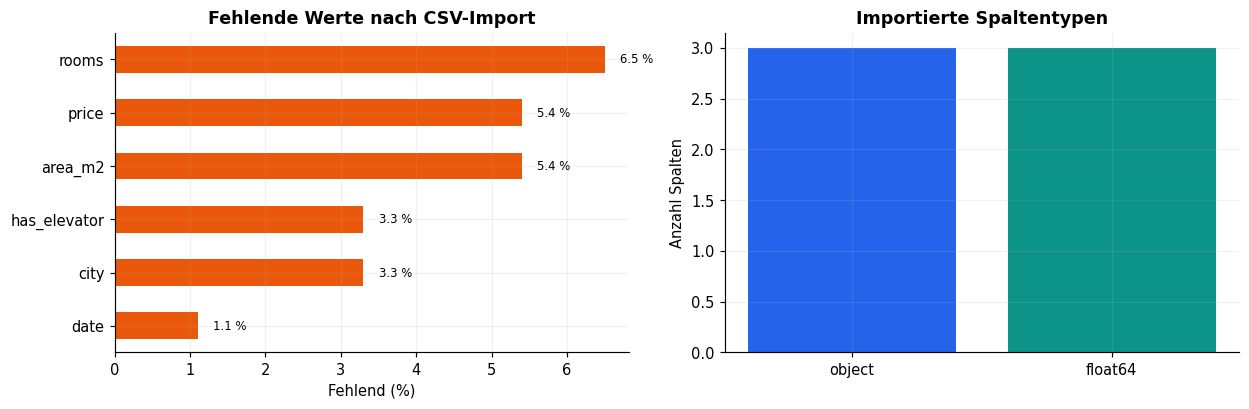

In [3]:
raw_types = df_raw.dtypes.astype(str).rename('Pandas-Typ')
raw_missing = pd.DataFrame({
    'Typ': raw_types,
    'Fehlende Werte': df_raw.isna().sum(),
    'Fehlend (%)': (100 * df_raw.isna().mean()).round(1),
})
display(raw_missing)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw_missing['Fehlend (%)'].sort_values().plot.barh(ax=axes[0], color=ORANGE)
axes[0].set(title='Fehlende Werte nach CSV-Import', xlabel='Fehlend (%)', ylabel='')
for i, value in enumerate(raw_missing['Fehlend (%)'].sort_values()):
    axes[0].text(value + .2, i, f'{value:.1f} %', va='center', fontsize=8)
dtype_counts = df_raw.dtypes.astype(str).value_counts()
axes[1].bar(dtype_counts.index, dtype_counts.values, color=[BLUE, TEAL, PURPLE][:len(dtype_counts)])
axes[1].set(title='Importierte Spaltentypen', ylabel='Anzahl Spalten')
plt.tight_layout()
plt.show()

## 1 · Spaltennamen, Strings, Typen und Duplikate

Wir vereinheitlichen die Spaltennamen und Zeichenketten und konvertieren die bekannten Zahlenfelder explizit. `Berlin`, `berlin` und ` Berlin ` sollen zu derselben Kategorie gehören. Danach entfernen wir Duplikate – **nach** der Normalisierung können zusätzliche Doppelungen erkennbar werden.

In [4]:
df = df_raw.copy()
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(' ', '_', regex=False))

for col in df.select_dtypes(include=['object', 'string']).columns:
    # Keine Umwandlung von echtem NaN in die Zeichenkette 'nan'.
    txt = df[col].astype('string').str.strip()
    txt = txt.mask(txt.isin(['', 'nan', 'none', 'null', '?', '--']))
    df[col] = txt.astype(object).where(txt.notna(), np.nan)

for col in ['city', 'has_elevator']:
    if col in df.columns:
        df[col] = df[col].str.lower()
for col in ['rooms', 'area_m2', 'price']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

before_duplicates = len(df)
exact_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
after_duplicates = len(df)

print('Duplikate entfernt:', exact_duplicates)
print('Zeilen vor / nach Bereinigung:', before_duplicates, '/', after_duplicates)
print('Bereinigte Spaltentypen:')
display(df.dtypes.rename('Typ').to_frame())
display(df.head(6))

Duplikate entfernt: 2
Zeilen vor / nach Bereinigung: 92 / 90
Bereinigte Spaltentypen:


,Typ
date,object
city,object
rooms,float64
area_m2,float64
price,float64
has_elevator,object


,date,city,rooms,area_m2,price,has_elevator
0,2025-01-03,berlin,2.0,45.0,245000.0,yes
1,2025-02-10,berlin,NaN,60.0,315000.0,no
2,2024-12-15,münchen,1.0,34.0,NaN,yes
3,2025-01-20,hamburg,3.0,85.0,520000.0,yes
4,2025-03-02,münchen,2.0,NaN,480000.0,no
5,2025-03-05,berlin,2.0,55.0,310000.0,unknown


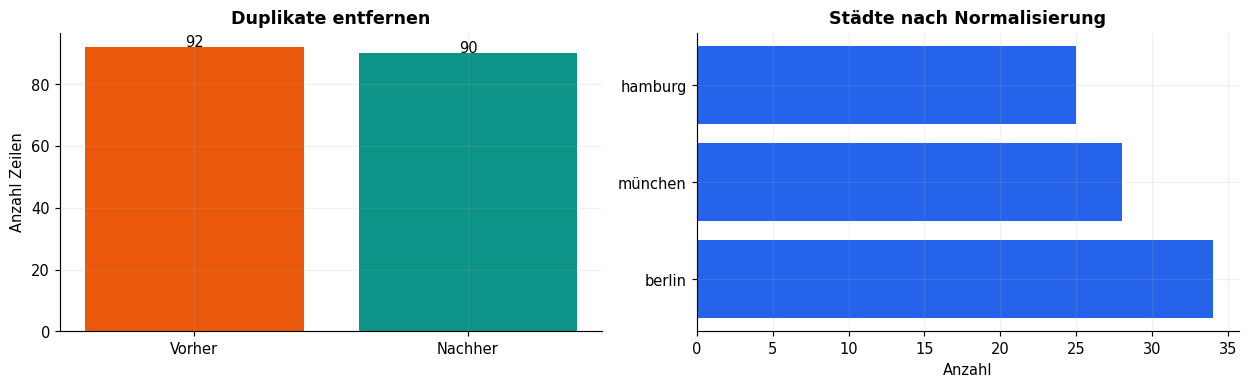

,Original,Normalisiert
0,Berlin,berlin
1,berlin,berlin
2,Berlin,berlin
3,BERLIN,berlin


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(['Vorher', 'Nachher'], [before_duplicates, after_duplicates], color=[ORANGE, TEAL])
axes[0].set(title='Duplikate entfernen', ylabel='Anzahl Zeilen')
for i, v in enumerate([before_duplicates, after_duplicates]):
    axes[0].text(i, v + .3, str(v), ha='center')

if 'city' in df.columns:
    raw_city = df_raw.get('city', pd.Series(dtype='object')).dropna().astype(str).str.strip().value_counts()
    cleaned_city = df['city'].dropna().value_counts()
    axes[1].barh(cleaned_city.index.astype(str), cleaned_city.values, color=BLUE)
    axes[1].set(title='Städte nach Normalisierung', xlabel='Anzahl')
else:
    axes[1].text(.5, .5, 'Keine Spalte city vorhanden', ha='center', transform=axes[1].transAxes)
    axes[1].set_axis_off()
plt.tight_layout()
plt.show()

# Mini-Beispiel: unterschiedliche Schreibweise, identische Kategorie
normalization_demo = pd.Series(['Berlin', 'berlin', ' Berlin ', 'BERLIN'])
display(pd.DataFrame({'Original': normalization_demo,
                      'Normalisiert': normalization_demo.str.strip().str.lower()}))

## 2 · Datumsfelder parsen und Datumsmerkmale bilden

Wie im Original werden Spalten mit `date`, `time` oder `datum` im Namen erkannt. Ungültige Datumsangaben werden mit `errors='coerce'` zu `NaT`. Aus gültigen Datumsangaben entstehen `year`, `month` und `dow` (`0 = Montag`, `6 = Sonntag`). Die ursprüngliche Datumsspalte wird vor der Modell-Vorbereitung entfernt, die abgeleiteten **numerischen Merkmale** bleiben.

In [6]:
date_cols = [col for col in df.columns if any(token in col for token in ['date', 'time', 'datum'])]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')
    df[f'{col}_year'] = df[col].dt.year
    df[f'{col}_month'] = df[col].dt.month
    df[f'{col}_dow'] = df[col].dt.dayofweek

print('Erkannte Datumsfelder:', date_cols)
example_cols = date_cols + [f'{col}_{suffix}' for col in date_cols for suffix in ['year', 'month', 'dow']]
if example_cols:
    display(df[example_cols].head(10))
else:
    print('In dieser CSV wurden keine Datumsfelder erkannt.')

Erkannte Datumsfelder: ['date']


,date,date_year,date_month,date_dow
0,2025-01-03,2025.0,1.0,4.0
1,2025-02-10,2025.0,2.0,0.0
2,2024-12-15,2024.0,12.0,6.0
3,2025-01-20,2025.0,1.0,0.0
4,2025-03-02,2025.0,3.0,6.0
5,2025-03-05,2025.0,3.0,2.0
6,2025-04-14,2025.0,4.0,0.0
7,2024-11-13,2024.0,11.0,2.0
8,2025-01-04,2025.0,1.0,5.0
9,2025-01-09,2025.0,1.0,3.0


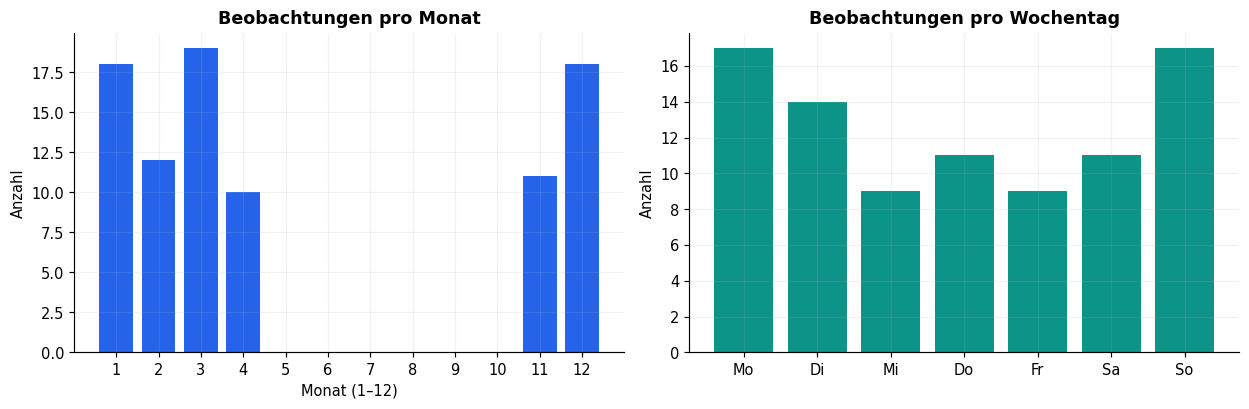

Ungültige/fehlende Datumsangaben: 2


In [7]:
if date_cols:
    col = date_cols[0]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    monthly = df[f'{col}_month'].value_counts().sort_index()
    axes[0].bar(monthly.index.astype(int), monthly.values, color=BLUE, width=.8)
    axes[0].set(title='Beobachtungen pro Monat', xlabel='Monat (1–12)', ylabel='Anzahl', xticks=np.arange(1, 13))

    by_dow = df[f'{col}_dow'].value_counts().reindex(range(7), fill_value=0)
    axes[1].bar(['Mo', 'Di', 'Mi', 'Do', 'Fr', 'Sa', 'So'], by_dow.values, color=TEAL)
    axes[1].set(title='Beobachtungen pro Wochentag', ylabel='Anzahl')
    plt.tight_layout()
    plt.show()
    print('Ungültige/fehlende Datumsangaben:', int(df[col].isna().sum()))

## 3 · Fehlende Werte verstehen und sichtbar machen

Für Imputation ist wichtig, **in welchen Spalten** und **bei welchen Zeilen** Angaben fehlen. Die linke Darstellung zeigt die Fehlerraten, die rechte visualisiert das Muster der fehlenden Felder (rot = fehlend). Die Missing-Indikatoren werden später an konkreten Imputationsbeispielen gezeigt.

,Anzahl,Anteil (%)
rooms,6,6.7
area_m2,5,5.6
price,4,4.4
has_elevator,3,3.3
city,3,3.3
date,2,2.2
date_year,2,2.2
date_month,2,2.2
date_dow,2,2.2


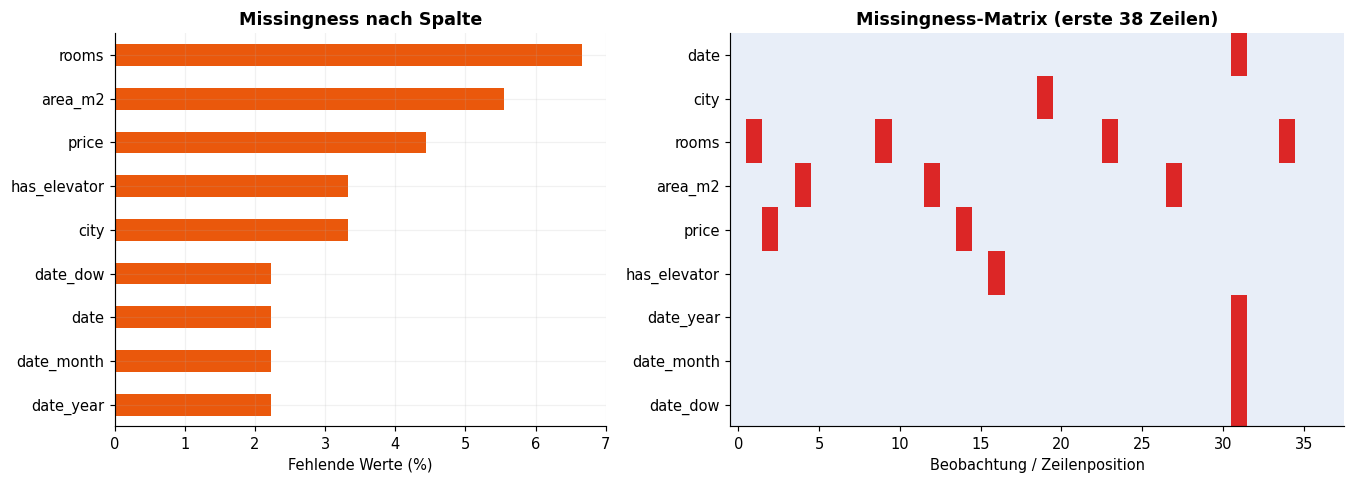

In [8]:
missing_count = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
display(pd.DataFrame({'Anzahl': missing_count, 'Anteil (%)': missing_pct.round(1)}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7), gridspec_kw={'width_ratios': [1, 1.25]})
missing_pct.sort_values().plot.barh(ax=axes[0], color=ORANGE)
axes[0].set(title='Missingness nach Spalte', xlabel='Fehlende Werte (%)', ylabel='')
matrix = df.isna().head(38).T.astype(int)
axes[1].imshow(matrix, aspect='auto', interpolation='nearest',
               cmap=ListedColormap([PALE, RED]), vmin=0, vmax=1)
axes[1].set(title='Missingness-Matrix (erste 38 Zeilen)',
            xlabel='Beobachtung / Zeilenposition', yticks=np.arange(len(matrix)),
            yticklabels=matrix.index)
axes[1].grid(False)
plt.tight_layout()
plt.show()

In [9]:
# Beispiel ohne Imputation: Ein Missing-Indikator speichert, ob ein Feld fehlte.
indicator_cols = [c for c in ['rooms', 'area_m2', 'city'] if c in df.columns]
missing_flags = df[indicator_cols].isna().astype(int).add_suffix('_fehlte')
example_indices = df[indicator_cols].isna().any(axis=1)
example_rows = pd.concat([df.loc[example_indices, indicator_cols],
                          missing_flags.loc[example_indices]], axis=1).head(10)
print('1 = ursprünglich fehlend, 0 = vorhanden')
display(example_rows)

1 = ursprünglich fehlend, 0 = vorhanden


,rooms,area_m2,city,rooms_fehlte,area_m2_fehlte,city_fehlte
1,NaN,60.0,berlin,1,0,0
4,2.0,NaN,münchen,0,1,0
9,NaN,85.0,münchen,1,0,0
12,3.0,NaN,münchen,0,1,0
19,1.0,37.0,NaN,0,0,1
23,NaN,60.0,münchen,1,0,0
27,3.0,NaN,berlin,0,1,0
34,NaN,44.0,münchen,1,0,0
49,3.0,65.0,NaN,0,0,1
53,2.0,NaN,münchen,0,1,0


## 4 · Zielspalte, Train/Test-Aufteilung und Data Leakage vermeiden

Das Original verwendet `price` als optionale Zielspalte. **Fehlende Zielwerte werden nicht imputiert**: Für eine überwachte Train/Test-Aufteilung nehmen wir nur Zeilen mit vorhandenem `price`. Die Roh-Datumsfelder werden entfernt, die daraus erzeugten Merkmale bleiben. Anschließend wird – wie im Original – reproduzierbar im Verhältnis **75 % Train / 25 % Test** geteilt.

Ein Beispiel mit Train- und Gesamtmedian zeigt, warum `fit()` erst **nach** dem Split aufgerufen wird: Der Testdatensatz soll die Vorbereitung nicht beeinflussen.

In [10]:
TARGET_COL = 'price' if 'price' in df.columns else None
if TARGET_COL:
    n_missing_target = int(df[TARGET_COL].isna().sum())
    df_use = df.loc[df[TARGET_COL].notna()].copy()
    y = df_use[TARGET_COL].astype(float)
    X = df_use.drop(columns=[TARGET_COL])
    print(f'Fehlende Zielwerte verworfen: {n_missing_target}')
else:
    df_use = df.copy()
    X, y = df_use.copy(), None
    print('Keine Zielspalte price vorhanden: Aufteilung nur für X.')

X_model = X.drop(columns=date_cols, errors='ignore')
num_cols = list(X_model.select_dtypes(include=[np.number]).columns)
cat_cols = list(X_model.select_dtypes(include=['object', 'category', 'string']).columns)

if not (num_cols or cat_cols):
    raise ValueError('Nach Entfernen der Datumsfelder sind keine vorbereitbaren Features übrig.')
if len(X_model) < 4:
    raise ValueError('Für diese Beispiele werden mindestens vier Beobachtungen benötigt.')

if y is not None:
    X_train, X_test, y_train, y_test = train_test_split(
        X_model, y, test_size=.25, random_state=RANDOM_STATE)
else:
    X_train, X_test = train_test_split(
        X_model, test_size=.25, random_state=RANDOM_STATE)
    y_train = y_test = None

print('Numerisch:', num_cols)
print('Kategorisch:', cat_cols)
print('Train:', X_train.shape, '| Test:', X_test.shape)
assert X_train.index.intersection(X_test.index).empty

Fehlende Zielwerte verworfen: 4
Numerisch: ['rooms', 'area_m2', 'date_year', 'date_month', 'date_dow']
Kategorisch: ['city', 'has_elevator']
Train: (64, 7) | Test: (22, 7)


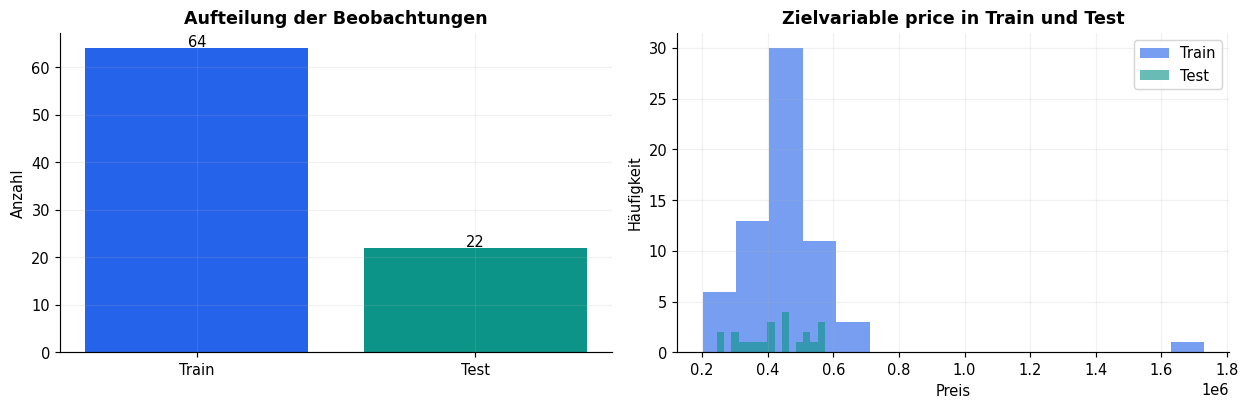

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['Train', 'Test'], [len(X_train), len(X_test)], color=[BLUE, TEAL])
axes[0].set(title='Aufteilung der Beobachtungen', ylabel='Anzahl')
for i, v in enumerate([len(X_train), len(X_test)]):
    axes[0].text(i, v + .25, str(v), ha='center')
if y_train is not None:
    axes[1].hist(y_train, bins=15, alpha=.62, color=BLUE, label='Train')
    axes[1].hist(y_test, bins=15, alpha=.62, color=TEAL, label='Test')
    axes[1].set(title='Zielvariable price in Train und Test', xlabel='Preis', ylabel='Häufigkeit')
    axes[1].legend()
else:
    axes[1].set_axis_off()
    axes[1].text(.5, .5, 'Keine Zielvariable price vorhanden', ha='center')
plt.tight_layout()
plt.show()

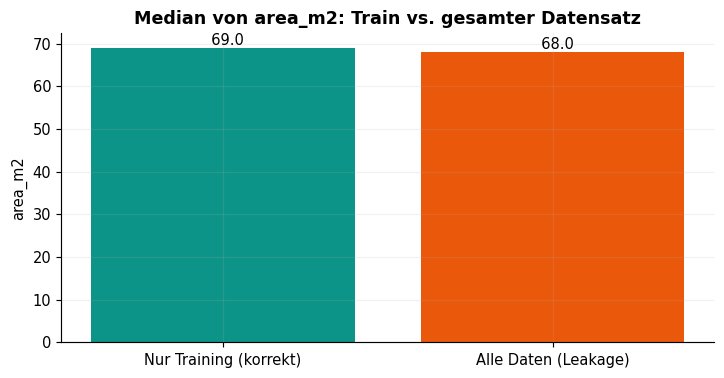

Für Imputation, Skalierung, Clipping und Kategorien gilt: fit(X_train), danach transform(X_test).


In [12]:
# Dieselbe Kennzahl aus verschiedenen Datenmengen:
leakage_col = 'area_m2' if 'area_m2' in num_cols else (num_cols[0] if num_cols else None)
if leakage_col:
    med_train = float(X_train[leakage_col].median())
    med_full = float(X_model[leakage_col].median())
    fig, ax = plt.subplots(figsize=(7, 3.7))
    ax.bar(['Nur Training (korrekt)', 'Alle Daten (Leakage)'],
           [med_train, med_full], color=[TEAL, ORANGE])
    ax.set(title=f'Median von {leakage_col}: Train vs. gesamter Datensatz', ylabel=leakage_col)
    for i, value in enumerate([med_train, med_full]):
        ax.text(i, value, f'  {value:.1f}', ha='center', va='bottom')
    plt.tight_layout(); plt.show()
    print('Für Imputation, Skalierung, Clipping und Kategorien gilt: fit(X_train), danach transform(X_test).')

## 5 · Imputation: numerisch, kategorisch und mit Indikator

Das Original verwendet **Median** für numerische Spalten und **häufigste Kategorie** für Texte. Beide Strategien werden hier zunächst einzeln durchgerechnet. Ein zusätzlicher **Missing-Indikator** kann festhalten, welche Beobachtungen ursprünglich unvollständig waren – auch nachdem die Lücken gefüllt sind.

Beispielspalte: area_m2 | gelernter Median: 69.0


,Vorher,Nach Median-Imputation
27,NaN,69.0
4,NaN,69.0
53,NaN,69.0
75,NaN,69.0


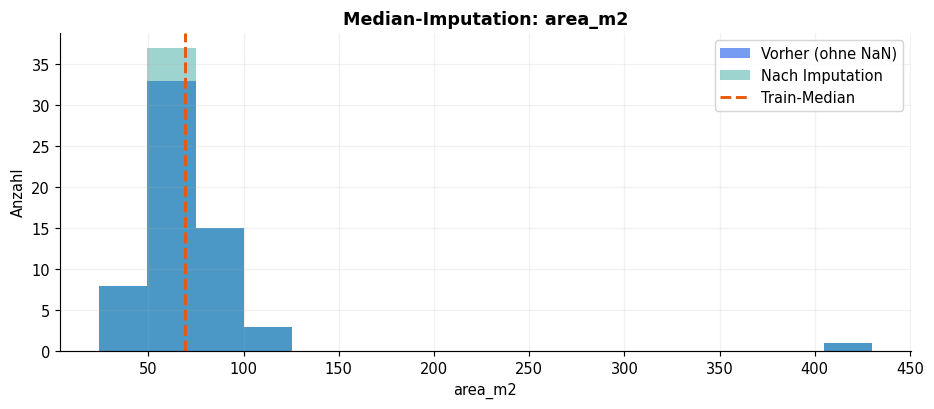

In [13]:
# Numerische Imputation – Strategie wird ausschließlich mit X_train gelernt.
if num_cols:
    num_missing = X_train[num_cols].isna().sum().sort_values(ascending=False)
    num_demo_col = 'area_m2' if 'area_m2' in num_cols and X_train['area_m2'].isna().any() else num_missing.index[0]
    imp_num_demo = SimpleImputer(strategy='median')
    num_input = X_train[[num_demo_col]]
    num_filled = imp_num_demo.fit_transform(num_input).ravel()
    numeric_compare = pd.DataFrame({'Vorher': num_input[num_demo_col].to_numpy(),
                                    'Nach Median-Imputation': num_filled}, index=num_input.index)
    print('Beispielspalte:', num_demo_col, '| gelernter Median:', float(imp_num_demo.statistics_[0]))
    display(numeric_compare.loc[num_input[num_demo_col].isna()].head(8))

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(num_input[num_demo_col].dropna(), bins=16, alpha=.63, color=BLUE, label='Vorher (ohne NaN)')
    ax.hist(num_filled, bins=16, alpha=.40, color=TEAL, label='Nach Imputation')
    ax.axvline(imp_num_demo.statistics_[0], color=ORANGE, linestyle='--', linewidth=2, label='Train-Median')
    ax.set(title=f'Median-Imputation: {num_demo_col}', xlabel=num_demo_col, ylabel='Anzahl')
    ax.legend(); plt.tight_layout(); plt.show()

Beispielspalte: city | häufigster Wert im Training: berlin


,Vorher,Nach Modus-Imputation
19,NaN,berlin
49,NaN,berlin


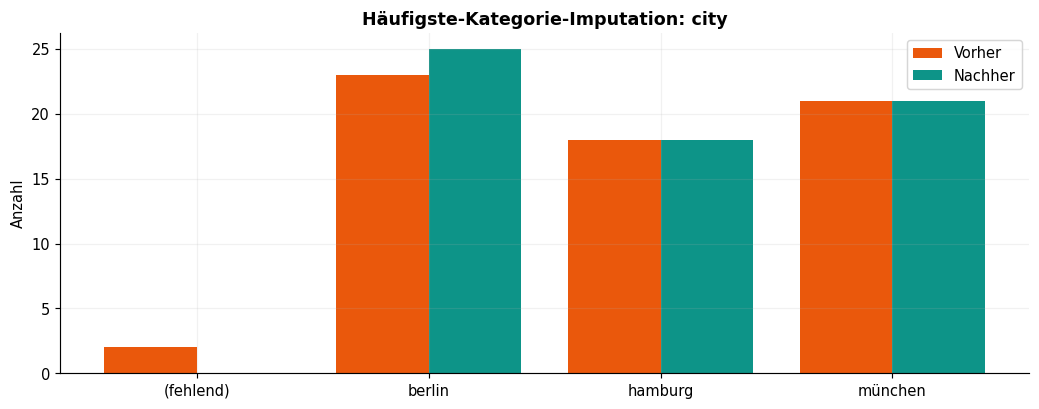

In [14]:
if cat_cols:
    cat_missing = X_train[cat_cols].isna().sum().sort_values(ascending=False)
    cat_demo_col = 'city' if 'city' in cat_cols and X_train['city'].isna().any() else cat_missing.index[0]
    imp_cat_demo = SimpleImputer(strategy='most_frequent')
    cat_filled = imp_cat_demo.fit_transform(X_train[[cat_demo_col]]).ravel()
    cat_compare = pd.DataFrame({'Vorher': X_train[cat_demo_col],
                                'Nach Modus-Imputation': cat_filled}, index=X_train.index)
    print('Beispielspalte:', cat_demo_col, '| häufigster Wert im Training:', imp_cat_demo.statistics_[0])
    display(cat_compare.loc[X_train[cat_demo_col].isna()].head(8))

    before_counts = X_train[cat_demo_col].fillna('(fehlend)').value_counts()
    after_counts = pd.Series(cat_filled).value_counts()
    categories = sorted(set(before_counts.index) | set(after_counts.index))
    before_plot = before_counts.reindex(categories, fill_value=0)
    after_plot = after_counts.reindex(categories, fill_value=0)
    xx = np.arange(len(categories))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(xx - .20, before_plot, .40, label='Vorher', color=ORANGE)
    ax.bar(xx + .20, after_plot, .40, label='Nachher', color=TEAL)
    ax.set(title=f'Häufigste-Kategorie-Imputation: {cat_demo_col}', ylabel='Anzahl',
           xticks=xx, xticklabels=categories)
    ax.legend(); plt.tight_layout(); plt.show()

Originale numerische Felder: 5 | zusätzliche Indikatoren: 5


,missingindicator_rooms,missingindicator_area_m2,missingindicator_date_year,missingindicator_date_month,missingindicator_date_dow
42,0.0,0.0,0.0,0.0,0.0
30,0.0,0.0,0.0,0.0,0.0
10,0.0,0.0,0.0,0.0,0.0
68,0.0,0.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0
41,0.0,0.0,0.0,0.0,0.0
33,0.0,0.0,0.0,0.0,0.0
37,0.0,0.0,0.0,0.0,0.0
48,0.0,0.0,0.0,0.0,0.0
47,0.0,0.0,0.0,0.0,0.0


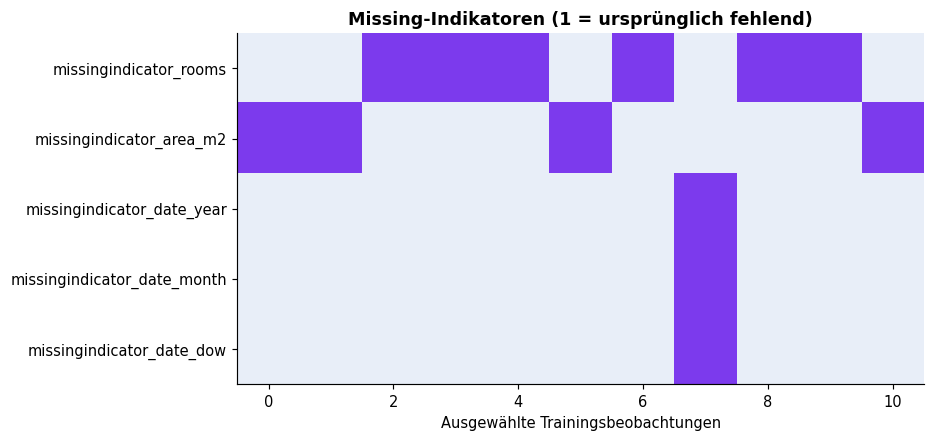

In [15]:
# SimpleImputer(add_indicator=True) ergänzt ausschließlich Flags für beim FIT vorhandene Lücken.
if num_cols:
    imp_with_flags = SimpleImputer(strategy='median', add_indicator=True)
    transformed_flags = imp_with_flags.fit_transform(X_train[num_cols])
    flag_names = imp_with_flags.get_feature_names_out(num_cols)
    flagged_train = pd.DataFrame(transformed_flags, columns=flag_names, index=X_train.index)
    generated_flags = [c for c in flagged_train if c.startswith('missingindicator_')]
    print('Originale numerische Felder:', len(num_cols), '| zusätzliche Indikatoren:', len(generated_flags))
    display(flagged_train[generated_flags].head(10) if generated_flags else flagged_train.head(5))
    if generated_flags:
        flagged_rows = flagged_train.loc[flagged_train[generated_flags].sum(axis=1) > 0, generated_flags].head(16)
        if len(flagged_rows):
            fig, ax = plt.subplots(figsize=(9, max(3, len(flagged_rows) * .30 + 1)))
            ax.imshow(flagged_rows.to_numpy().T, aspect='auto', interpolation='nearest',
                      cmap=ListedColormap([PALE, PURPLE]), vmin=0, vmax=1)
            ax.set(title='Missing-Indikatoren (1 = ursprünglich fehlend)',
                   yticks=np.arange(len(generated_flags)), yticklabels=generated_flags,
                   xlabel='Ausgewählte Trainingsbeobachtungen')
            ax.grid(False); plt.tight_layout(); plt.show()

## 6 · One-Hot-Encoding kategorischer Merkmale

Kategorien werden in binäre Spalten umgewandelt. `drop='if_binary'` spart bei binären Merkmalen eine der beiden Dummy-Spalten. Mit `handle_unknown='ignore'` kann die Pipeline auch eine **im Training nicht gesehene Stadt** verarbeiten; ihr Teilvektor besteht dann aus Nullen. Achtung: Bei `drop='if_binary'` können Nullen auch die Referenzkategorie bedeuten.

Kategorische Felder: ['city', 'has_elevator']
One-Hot-Spalten: ['city_berlin', 'city_hamburg', 'city_münchen', 'has_elevator_no', 'has_elevator_unknown', 'has_elevator_yes']


,city_berlin,city_hamburg,city_münchen,has_elevator_no,has_elevator_unknown,has_elevator_yes
42,1.0,0.0,0.0,1.0,0.0,0.0
30,0.0,0.0,1.0,0.0,1.0,0.0
10,1.0,0.0,0.0,0.0,0.0,1.0
68,1.0,0.0,0.0,0.0,0.0,1.0
6,0.0,1.0,0.0,0.0,1.0,0.0
41,0.0,0.0,1.0,0.0,0.0,1.0
33,1.0,0.0,0.0,0.0,0.0,1.0
37,1.0,0.0,0.0,1.0,0.0,0.0


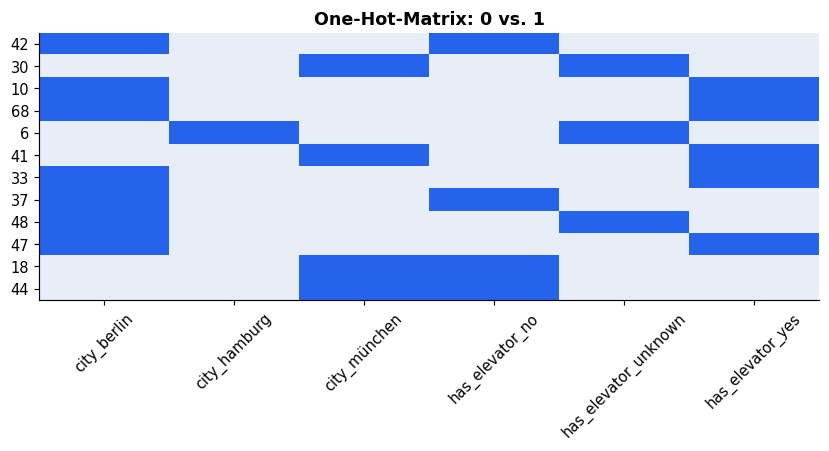

In [16]:
def make_ohe():
    """Kompatibel mit aktuellen und älteren scikit-learn-Versionen."""
    try:
        return OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False)
    except TypeError:  # vor scikit-learn 1.2
        return OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse=False)

if cat_cols:
    cat_imputer = SimpleImputer(strategy='most_frequent')
    train_cat_filled = cat_imputer.fit_transform(X_train[cat_cols])
    encoder = make_ohe()
    train_hot = encoder.fit_transform(train_cat_filled)
    hot_names = encoder.get_feature_names_out(cat_cols)
    hot_df = pd.DataFrame(train_hot, columns=hot_names, index=X_train.index)
    print('Kategorische Felder:', cat_cols)
    print('One-Hot-Spalten:', list(hot_names))
    display(hot_df.head(8))

    fig, ax = plt.subplots(figsize=(max(8, len(hot_names) * .9 + 2), 4.4))
    view = hot_df.iloc[:12, :12]
    ax.imshow(view.to_numpy(), aspect='auto', interpolation='nearest',
              cmap=ListedColormap([PALE, BLUE]), vmin=0, vmax=1)
    ax.set(title='One-Hot-Matrix: 0 vs. 1', xticks=np.arange(view.shape[1]),
           xticklabels=view.columns, yticks=np.arange(view.shape[0]),
           yticklabels=view.index.astype(str))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(False); plt.tight_layout(); plt.show()

In [17]:
if cat_cols:
    known_row = X_train[cat_cols].iloc[[0]].copy()
    unseen_row = known_row.copy()
    unknown_col = 'city' if 'city' in cat_cols else cat_cols[0]
    unseen_row[unknown_col] = 'im_training_nicht_gesehen'
    known_hot = encoder.transform(cat_imputer.transform(known_row))
    unseen_hot = encoder.transform(cat_imputer.transform(unseen_row))
    preview = pd.DataFrame(np.vstack([known_hot, unseen_hot]),
                           columns=hot_names, index=['bekannte Kategorie', 'unbekannte Kategorie'])
    print(f'Beispiel: unbekannter Wert in {unknown_col!r} wird ohne Fehler kodiert.')
    display(preview)

Beispiel: unbekannter Wert in 'city' wird ohne Fehler kodiert.


/opt/pyvenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,city_berlin,city_hamburg,city_münchen,has_elevator_no,has_elevator_unknown,has_elevator_yes
bekannte Kategorie,1.0,0.0,0.0,1.0,0.0,0.0
unbekannte Kategorie,0.0,0.0,0.0,1.0,0.0,0.0


## 7 · Drei Skalierungsvarianten vergleichen

Wie im Original stehen drei Methoden zur Wahl:

- **StandardScaler (Z-Score):** zieht den Mittelwert ab und teilt durch die Standardabweichung.
- **MinMaxScaler:** bildet die Werte des Trainingsbereichs auf `[0, 1]` ab.
- **RobustScaler:** nutzt Median und Interquartilsabstand (IQR) und ist gegenüber Ausreißern robuster.

Wir verwenden dieselbe **imputierte** Trainingsspalte für alle drei Varianten. Die Skalierer werden immer erst auf den Trainingswerten gefittet. Ein Ausreißer kann die Transformation stark beeinflussen; deshalb folgt im nächsten Abschnitt das Kappen.

Gleiche Beobachtungen, unterschiedliche Skalen:


,Original,Z-Score,MinMax,Robust
42,65.0,-0.178,0.101,-0.219
30,71.0,-0.054,0.116,0.110
10,64.0,-0.199,0.099,-0.274
68,102.0,0.588,0.192,1.808
6,59.0,-0.302,0.086,-0.548
41,56.0,-0.364,0.079,-0.712
33,38.0,-0.737,0.034,-1.699
37,69.0,-0.095,0.111,0.000


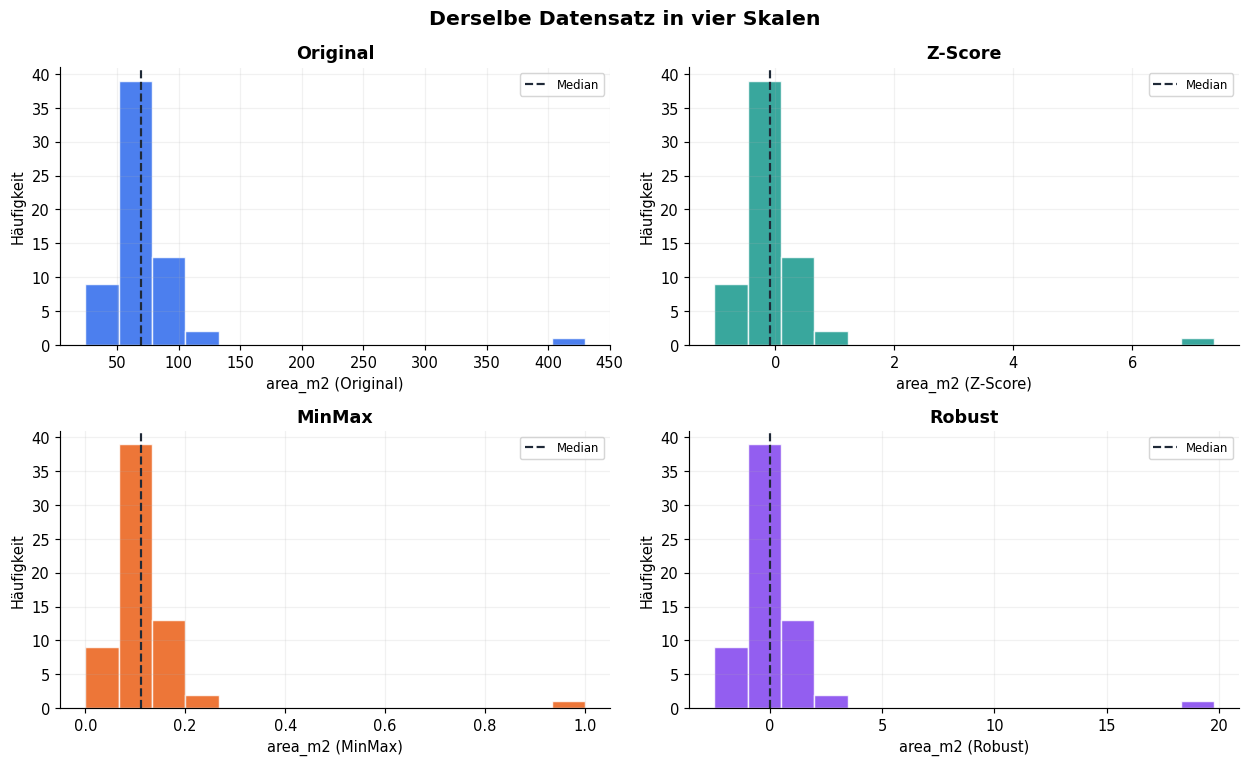

In [18]:
if num_cols:
    scale_col = 'area_m2' if 'area_m2' in num_cols else num_cols[0]
    scale_median = SimpleImputer(strategy='median')
    scale_values = scale_median.fit_transform(X_train[[scale_col]])
    scaler_examples = {
        'Z-Score': StandardScaler(),
        'MinMax': MinMaxScaler(feature_range=(0, 1)),
        'Robust': RobustScaler(quantile_range=(25, 75)),
    }
    scales = {'Original': scale_values.ravel()}
    for name, model in scaler_examples.items():
        scales[name] = model.fit_transform(scale_values).ravel()
    compare_scales = pd.DataFrame(scales, index=X_train.index)
    print('Gleiche Beobachtungen, unterschiedliche Skalen:')
    display(compare_scales.head(8).round(3))

    fig, axes = plt.subplots(2, 2, figsize=(12, 7.4))
    scale_colors = {'Original': BLUE, 'Z-Score': TEAL, 'MinMax': ORANGE, 'Robust': PURPLE}
    for ax, (title, vals) in zip(axes.flat, scales.items()):
        ax.hist(vals, bins=15, color=scale_colors[title], alpha=.82, edgecolor='white')
        ax.axvline(float(np.median(vals)), color='#1f2937', linestyle='--', label='Median')
        ax.set(title=title, xlabel=f'{scale_col} ({title})', ylabel='Häufigkeit')
        ax.legend(fontsize=8)
    fig.suptitle('Derselbe Datensatz in vier Skalen', fontsize=14, weight='bold')
    plt.tight_layout(); plt.show()

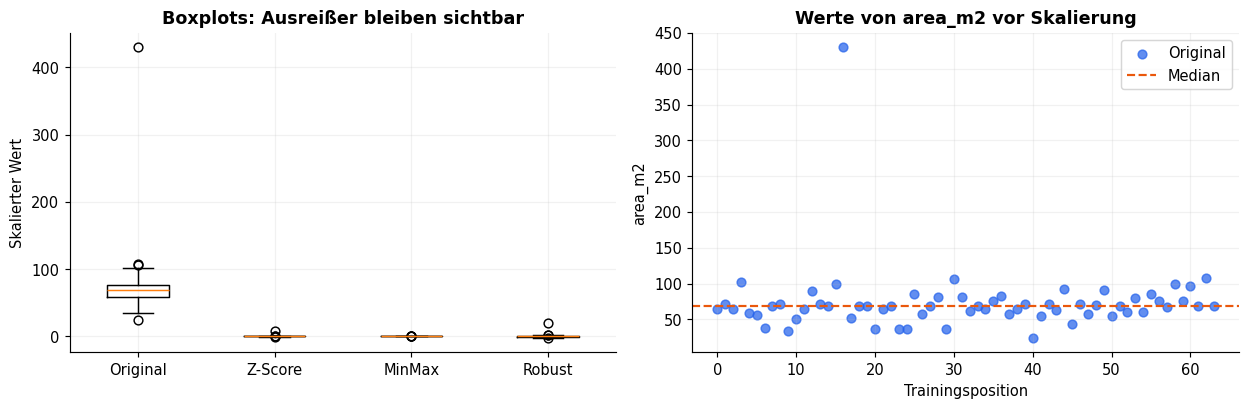

Interpretation: Skalieren entfernt weder fehlende Werte noch Ausreißer automatisch.


In [19]:
if num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].boxplot([scales[k] for k in ['Original', 'Z-Score', 'MinMax', 'Robust']],
                    tick_labels=['Original', 'Z-Score', 'MinMax', 'Robust'], showfliers=True)
    axes[0].set(title='Boxplots: Ausreißer bleiben sichtbar', ylabel='Skalierter Wert')
    axes[1].scatter(np.arange(len(scale_values)), scale_values.ravel(), color=BLUE, alpha=.72, label='Original')
    axes[1].axhline(np.median(scale_values), color=ORANGE, linestyle='--', label='Median')
    axes[1].set(title=f'Werte von {scale_col} vor Skalierung', xlabel='Trainingsposition', ylabel=scale_col)
    axes[1].legend()
    plt.tight_layout(); plt.show()
    print('Interpretation: Skalieren entfernt weder fehlende Werte noch Ausreißer automatisch.')

## 8 · Ausreißer-Kappen mit Quantilen (Winsorizing)

Das Original verwendet einen eigenen `QuantileClipper` mit **1 %- und 99 %-Quantil**. Werte unterhalb bzw. oberhalb dieser Trainingsgrenzen werden auf den jeweiligen Grenzwert gesetzt – nicht gelöscht. Zusätzlich zeigen wir zu Lernzwecken eine stärkere Variante mit **5 % / 95 %**, weil man die Wirkung im Diagramm deutlicher sieht. Die endgültige Pipeline verwendet weiterhin **1 % / 99 %** wie das Original.

In [20]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Clippt jede numerische Spalte anhand von TRAININGS-Quantilen."""
    def __init__(self, q_low=0.01, q_high=0.99):
        self.q_low = q_low
        self.q_high = q_high

    def fit(self, X, y=None):
        if not (0 <= self.q_low < self.q_high <= 1):
            raise ValueError('Erwartet: 0 <= q_low < q_high <= 1.')
        values = np.asarray(X, dtype=float)
        if values.ndim != 2:
            raise ValueError('X muss eine 2D-Matrix sein.')
        self.n_features_in_ = values.shape[1]
        self.lower_ = np.nanquantile(values, self.q_low, axis=0)
        self.upper_ = np.nanquantile(values, self.q_high, axis=0)
        return self

    def transform(self, X):
        check_is_fitted(self, ['lower_', 'upper_'])
        values = np.asarray(X, dtype=float)
        if values.ndim != 2 or values.shape[1] != self.n_features_in_:
            raise ValueError('Spaltenanzahl in transform() passt nicht zu fit().')
        return np.clip(values, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, ['lower_', 'upper_'])
        if input_features is None:
            return np.asarray([f'x{i}' for i in range(self.n_features_in_)], dtype=object)
        return np.asarray(input_features, dtype=object)

print('QuantileClipper definiert. Seine Grenzen entstehen erst durch fit(X_train).')

QuantileClipper definiert. Seine Grenzen entstehen erst durch fit(X_train).


Quantil-Grenzen area_m2 (1 % / 99 %): 30.3 / 227.14
Quantil-Grenzen area_m2 (5 % / 95 %): 37.0 / 101.55


,Original,1 % / 99 %,5 % / 95 %
21,430.0,227.14,101.55
16,108.0,108.00,101.55
81,106.0,106.00,101.55
68,102.0,102.00,101.55
78,99.0,99.00,99.00
86,99.0,99.00,99.00
63,97.0,97.00,97.00
60,93.0,93.00,93.00


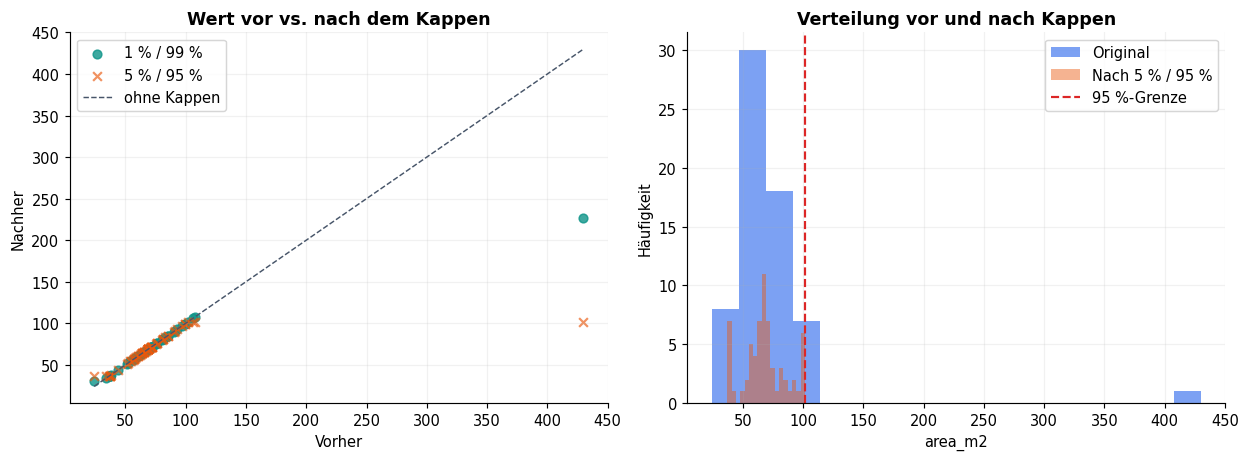

In [21]:
if num_cols:
    clip_values = scale_values             # Bereits mit Trainingsmedian aufgefüllt
    mild = QuantileClipper(.01, .99).fit(clip_values)
    strong = QuantileClipper(.05, .95).fit(clip_values)
    clipped_mild = mild.transform(clip_values).ravel()
    clipped_strong = strong.transform(clip_values).ravel()
    clip_comparison = pd.DataFrame({
        'Original': clip_values.ravel(),
        '1 % / 99 %': clipped_mild,
        '5 % / 95 %': clipped_strong,
    }, index=X_train.index)
    print(f'Quantil-Grenzen {scale_col} (1 % / 99 %):', mild.lower_[0].round(2), '/', mild.upper_[0].round(2))
    print(f'Quantil-Grenzen {scale_col} (5 % / 95 %):', strong.lower_[0].round(2), '/', strong.upper_[0].round(2))
    display(clip_comparison.sort_values('Original', ascending=False).head(8))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].scatter(clip_values.ravel(), clipped_mild, alpha=.8, color=TEAL, label='1 % / 99 %')
    axes[0].scatter(clip_values.ravel(), clipped_strong, alpha=.65, color=ORANGE, marker='x', label='5 % / 95 %')
    lo, hi = float(np.min(clip_values)), float(np.max(clip_values))
    axes[0].plot([lo, hi], [lo, hi], '--', color='#475569', linewidth=1, label='ohne Kappen')
    axes[0].set(title='Wert vor vs. nach dem Kappen', xlabel='Vorher', ylabel='Nachher')
    axes[0].legend()
    axes[1].hist(clip_values.ravel(), bins=18, color=BLUE, alpha=.6, label='Original')
    axes[1].hist(clipped_strong, bins=18, color=ORANGE, alpha=.45, label='Nach 5 % / 95 %')
    axes[1].axvline(strong.upper_[0], color=RED, linestyle='--', label='95 %-Grenze')
    axes[1].set(title='Verteilung vor und nach Kappen', xlabel=scale_col, ylabel='Häufigkeit')
    axes[1].legend()
    plt.tight_layout(); plt.show()

## 9 · `Pipeline` und `ColumnTransformer`: alles verbinden

Die Abfolge aus dem Original bleibt gleich:

**Numerisch:** `SimpleImputer(median)` → `QuantileClipper(0.01, 0.99)` → gewählter Skalierer.

**Kategorisch:** `SimpleImputer(most_frequent)` → `OneHotEncoder(handle_unknown='ignore', drop='if_binary')`.

`ColumnTransformer` führt beide Wege zusammen. Die ursprünglichen Datumsspalten wurden zuvor entfernt, die numerischen Datumsmerkmale werden mitverarbeitet. Im Flussdiagramm erkennt man, dass die **Transformationsparameter im Training** gelernt werden und der Testsatz dieselbe fertige Transformation nutzt.

In [22]:
def choose_scaler(kind):
    if kind == 'zscore':
        return StandardScaler()
    if kind == 'minmax':
        return MinMaxScaler(feature_range=(0, 1))
    if kind == 'robust':
        return RobustScaler(quantile_range=(25, 75))
    raise ValueError("SCALE_KIND muss 'zscore', 'minmax' oder 'robust' sein.")


def make_preprocess(kind='zscore'):
    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('clip', QuantileClipper(q_low=.01, q_high=.99)),
        ('scaler', choose_scaler(kind)),
    ])
    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', make_ohe()),
    ])
    return ColumnTransformer(
        transformers=[
            ('num', numeric_pipeline, num_cols),
            ('cat', categorical_pipeline, cat_cols),
        ],
        remainder='drop', verbose_feature_names_out=True,
    )

preprocess = make_preprocess(SCALE_KIND)
print(preprocess)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('clip', QuantileClipper()),
                                                 ('scaler', StandardScaler())]),
                                 ['rooms', 'area_m2', 'date_year', 'date_month',
                                  'date_dow']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
             

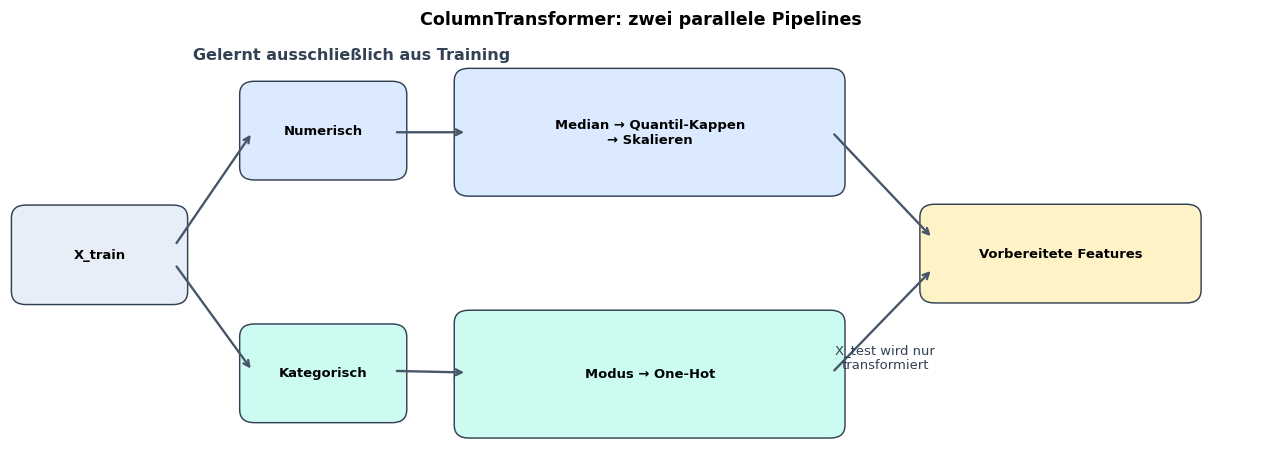

In [23]:
# Schematische Darstellung des gerade definierten Datenflusses
fig, ax = plt.subplots(figsize=(12.3, 4.6))
ax.set_xlim(0, 13.8); ax.set_ylim(0, 5.3); ax.axis('off')

def node(x, y, w, h, s, fc):
    p = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=.14,rounding_size=.16',
                       facecolor=fc, edgecolor='#334155', linewidth=1)
    ax.add_patch(p)
    ax.text(x+w/2, y+h/2, s, ha='center', va='center', fontsize=9, weight='bold')

def arrow(start, end):
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='->', color='#475569', lw=1.6,
                                connectionstyle='arc3,rad=0'))

node(.15, 2.08, 1.65, .95, 'X_train', PALE)
node(2.65, 3.62, 1.55, .94, 'Numerisch', '#dbeafe')
node(2.65, .62, 1.55, .94, 'Kategorisch', '#ccfbf1')
node(5.0, 3.42, 4.0, 1.3, 'Median → Quantil-Kappen\n→ Skalieren', '#dbeafe')
node(5.0, .43, 4.0, 1.3, 'Modus → One-Hot', '#ccfbf1')
node(10.1, 2.1, 2.8, .94, 'Vorbereitete Features', '#fef3c7')
arrow((1.8, 2.67), (2.65, 4.07)); arrow((1.8, 2.44), (2.65, 1.12))
arrow((4.2, 4.07), (5.0, 4.07)); arrow((4.2, 1.12), (5.0, 1.1))
arrow((9., 4.07), (10.1, 2.76)); arrow((9., 1.1), (10.1, 2.38))
ax.text(2.0, 4.97, 'Gelernt ausschließlich aus Training', fontsize=11, weight='bold', color='#334155')
ax.text(9.58, 1.15, 'X_test wird nur\ntransformiert', fontsize=9, color='#334155', ha='center')
ax.set_title('ColumnTransformer: zwei parallele Pipelines', pad=6)
plt.tight_layout(); plt.show()

In [24]:
# Keine Parameter auf X_test fitten!
if y_train is not None:
    preprocess.fit(X_train, y_train)
else:
    preprocess.fit(X_train)
train_array = preprocess.transform(X_train)
test_array = preprocess.transform(X_test)

try:
    feat_names = preprocess.get_feature_names_out()
except Exception:
    # Rückfall für ältere scikit-learn-Versionen
    feat_names = np.asarray([f'f{i}' for i in range(train_array.shape[1])])

X_train_pre_df = pd.DataFrame(train_array, columns=feat_names, index=X_train.index)
X_test_pre_df = pd.DataFrame(test_array, columns=feat_names, index=X_test.index)

print('Vorher: Train', X_train.shape, '| Test', X_test.shape)
print('Nachher: Train', X_train_pre_df.shape, '| Test', X_test_pre_df.shape)
print('Neue Feature-Namen:', list(X_train_pre_df.columns))
display(X_train_pre_df.head(6).round(3))
assert X_train_pre_df.shape[1] == X_test_pre_df.shape[1]
assert X_train_pre_df.isna().sum().sum() == 0
assert X_test_pre_df.isna().sum().sum() == 0
print('Prüfung OK: identische Spaltenzahl; keine fehlenden Werte in Train oder Test.')

Vorher: Train (64, 7) | Test (22, 7)
Nachher: Train (64, 11) | Test (22, 11)
Neue Feature-Namen: ['num__rooms', 'num__area_m2', 'num__date_year', 'num__date_month', 'num__date_dow', 'cat__city_berlin', 'cat__city_hamburg', 'cat__city_münchen', 'cat__has_elevator_no', 'cat__has_elevator_unknown', 'cat__has_elevator_yes']


,num__rooms,num__area_m2,num__date_year,num__date_month,num__date_dow,cat__city_berlin,cat__city_hamburg,cat__city_münchen,cat__has_elevator_no,cat__has_elevator_unknown,cat__has_elevator_yes
42,-0.255,-0.209,0.674,-0.956,-0.822,1.0,0.0,0.0,1.0,0.0,0.0
30,-1.423,0.018,0.674,-0.956,0.483,0.0,0.0,1.0,0.0,1.0,0.0
10,0.912,-0.247,-1.483,1.528,0.048,1.0,0.0,0.0,0.0,0.0,1.0
68,2.080,1.190,-1.483,1.302,0.483,1.0,0.0,0.0,0.0,0.0,1.0
6,-0.255,-0.436,0.674,-0.279,-1.257,0.0,1.0,0.0,0.0,1.0,0.0
41,-0.255,-0.549,0.674,-0.956,-0.387,0.0,0.0,1.0,0.0,0.0,1.0


Prüfung OK: identische Spaltenzahl; keine fehlenden Werte in Train oder Test.


### Diagnostik: Was hat die Pipeline verändert?

**1.** Fehlende Werte wurden aufgefüllt. **2.** Aus zwei kategorialen Spalten können mehrere One-Hot-Spalten werden. **3.** Die ersten transformierten Beobachtungen lassen sich in einer Matrix betrachten. Die folgenden Diagramme zeigen alle drei Effekte.

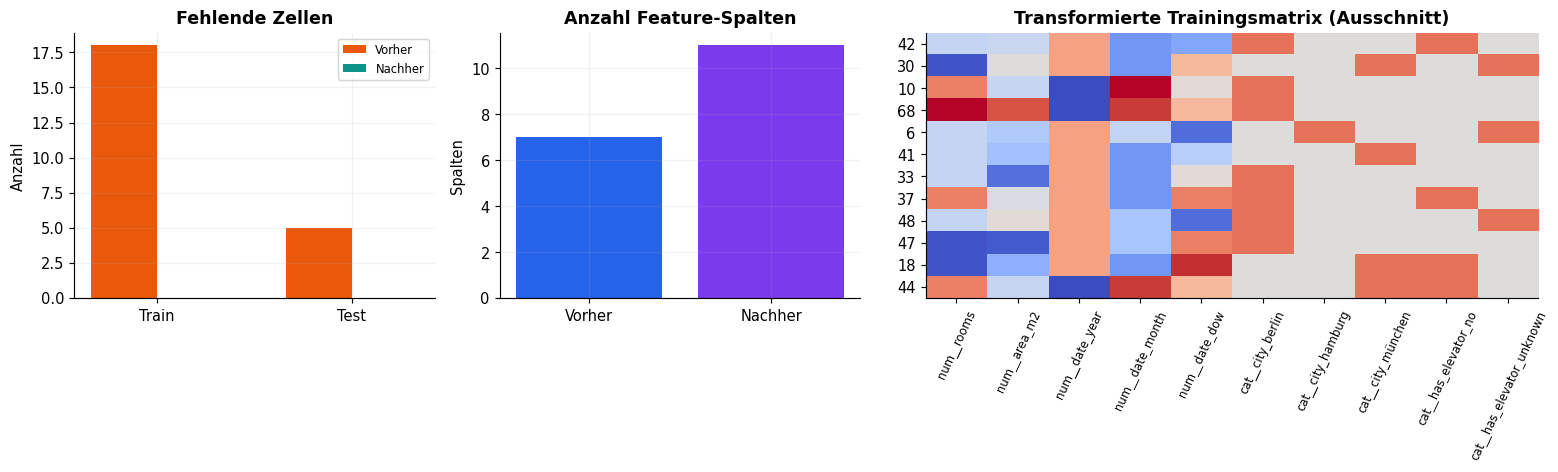

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1, 1, 1.7]})
na_before = [int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum())]
na_after = [int(X_train_pre_df.isna().sum().sum()), int(X_test_pre_df.isna().sum().sum())]
xx = np.arange(2)
axes[0].bar(xx - .17, na_before, .34, color=ORANGE, label='Vorher')
axes[0].bar(xx + .17, na_after, .34, color=TEAL, label='Nachher')
axes[0].set(title='Fehlende Zellen', xticks=xx, xticklabels=['Train', 'Test'], ylabel='Anzahl')
axes[0].legend(fontsize=8)
axes[1].bar(['Vorher', 'Nachher'], [X_train.shape[1], X_train_pre_df.shape[1]], color=[BLUE, PURPLE])
axes[1].set(title='Anzahl Feature-Spalten', ylabel='Spalten')

matrix = X_train_pre_df.iloc[:12, :min(10, X_train_pre_df.shape[1])]
plot_values = matrix.to_numpy(dtype=float)
limit = max(1., float(np.nanquantile(np.abs(plot_values), .97)))
axes[2].imshow(np.clip(plot_values, -limit, limit), cmap='coolwarm', aspect='auto',
               vmin=-limit, vmax=limit, interpolation='nearest')
axes[2].set(title='Transformierte Trainingsmatrix (Ausschnitt)',
            xticks=np.arange(matrix.shape[1]), xticklabels=matrix.columns,
            yticks=np.arange(matrix.shape[0]), yticklabels=matrix.index.astype(str))
axes[2].tick_params(axis='x', rotation=65, labelsize=8)
axes[2].grid(False)
plt.tight_layout(); plt.show()

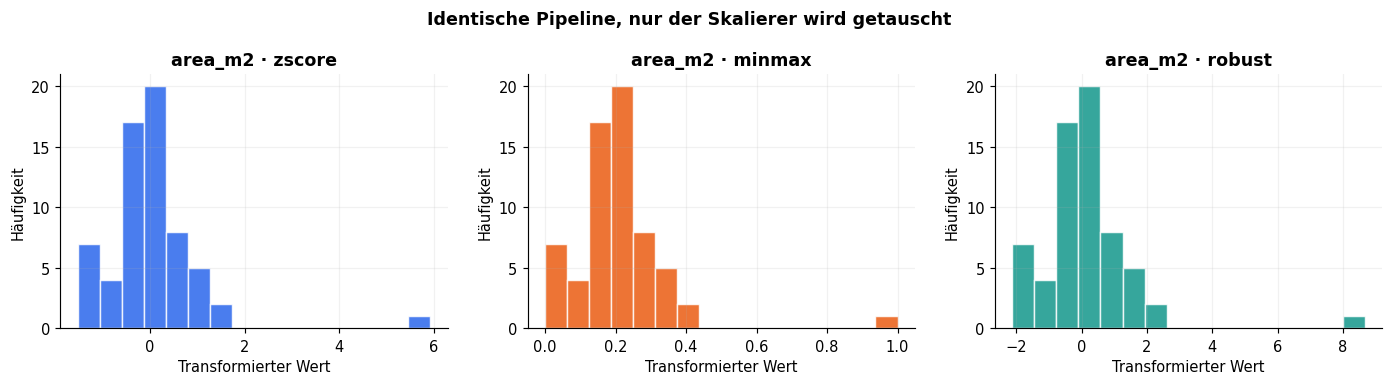

In [26]:
# Dasselbe Pipeline-Schema mit allen drei vorhandenen Skalierungsarten:
# Es wird jedes Mal NUR im Training gefittet.
if num_cols:
    compare_feature = 'area_m2' if 'area_m2' in num_cols else num_cols[0]
    transformed_by_scaler = {}
    for kind in ['zscore', 'minmax', 'robust']:
        p = make_preprocess(kind)
        p.fit(X_train)
        names = p.get_feature_names_out()
        temp = pd.DataFrame(p.transform(X_train), columns=names, index=X_train.index)
        name = f'num__{compare_feature}'
        if name not in temp.columns:
            name = next(col for col in temp.columns if col.endswith(f'__{compare_feature}'))
        transformed_by_scaler[kind] = temp[name]

    fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.7))
    for ax, (name, v), color in zip(axes, transformed_by_scaler.items(), [BLUE, ORANGE, TEAL]):
        ax.hist(v, bins=16, color=color, edgecolor='white', alpha=.83)
        ax.set(title=f'{compare_feature} · {name}', xlabel='Transformierter Wert', ylabel='Häufigkeit')
    fig.suptitle('Identische Pipeline, nur der Skalierer wird getauscht', weight='bold')
    plt.tight_layout(); plt.show()

In [27]:
# Kontrolle: Unbekannte Kategorien im Test dürfen die Spaltenanzahl nicht ändern.
if cat_cols:
    synthetic_test = X_test.iloc[[0]].copy()
    unknown_col = 'city' if 'city' in cat_cols else cat_cols[0]
    synthetic_test[unknown_col] = 'nicht_im_training_gesehen'
    unseen_transformed = preprocess.transform(synthetic_test)
    print(f'Unbekannte Kategorie in {unknown_col}: Transformation läuft.')
    print('Feature-Anzahl, unverändert:', unseen_transformed.shape[1], '==', X_train_pre_df.shape[1])
    assert unseen_transformed.shape[1] == X_train_pre_df.shape[1]

print('\nBeschreibung ausgewählter verarbeiteter Features:')
display(X_train_pre_df.describe().T.head(12).round(3))

Unbekannte Kategorie in city: Transformation läuft.
Feature-Anzahl, unverändert: 11 == 11

Beschreibung ausgewählter verarbeiteter Features:


/opt/pyvenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:261: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,count,mean,std,min,25%,50%,75%,max
num__rooms,64.0,-0.000,1.008,-1.423,-0.255,-0.255,0.912,2.080
num__area_m2,64.0,0.000,1.008,-1.521,-0.445,-0.058,0.245,5.921
num__date_year,64.0,-0.000,1.008,-1.483,-1.483,0.674,0.674,0.674
num__date_month,64.0,0.000,1.008,-0.956,-0.730,-0.504,1.302,1.528
num__date_dow,64.0,0.000,1.008,-1.257,-0.931,0.048,0.918,1.353
cat__city_berlin,64.0,0.391,0.492,0.000,0.000,0.000,1.000,1.000
cat__city_hamburg,64.0,0.281,0.453,0.000,0.000,0.000,1.000,1.000
cat__city_münchen,64.0,0.328,0.473,0.000,0.000,0.000,1.000,1.000
cat__has_elevator_no,64.0,0.375,0.488,0.000,0.000,0.000,1.000,1.000
cat__has_elevator_unknown,64.0,0.109,0.315,0.000,0.000,0.000,0.000,1.000


## 10 · Export und Wieder-Einlesen der vorbereiteten Daten

Wie im Original speichern wir die aufbereiteten Feature-Matrizen als **`prepared_train.csv`** und **`prepared_test.csv`**. Die Reihenfolge und Anzahl der Spalten stimmen überein. Das Ziel `price` gehört weiterhin zu `y_train` / `y_test` und ist nicht Teil der exportierten Feature-Matrizen.

Beim erneuten Ausführen im eigenen Arbeitsordner werden vorhandene Dateien mit diesen Namen überschrieben.

In [28]:
train_export = Path('prepared_train.csv')
test_export = Path('prepared_test.csv')
X_train_pre_df.to_csv(train_export, index=False)
X_test_pre_df.to_csv(test_export, index=False)

loaded_train = pd.read_csv(train_export)
loaded_test = pd.read_csv(test_export)
assert list(loaded_train.columns) == list(loaded_test.columns)
assert loaded_train.shape == X_train_pre_df.shape
assert loaded_test.shape == X_test_pre_df.shape

print(f'Export erfolgreich: {train_export.resolve()} — {loaded_train.shape}')
print(f'Export erfolgreich: {test_export.resolve()} — {loaded_test.shape}')
print('Prüfung: beide CSVs lassen sich wieder einlesen und haben dieselben Features.')

Export erfolgreich: /mnt/data/_akib3_notebook_test/prepared_train.csv — (64, 11)
Export erfolgreich: /mnt/data/_akib3_notebook_test/prepared_test.csv — (22, 11)
Prüfung: beide CSVs lassen sich wieder einlesen und haben dieselben Features.


---
### Zusammenfassung und kleine Übungen **innerhalb der vorhandenen Themen**

1. **Missingness:** Vergleiche die roten Felder in der Matrix vor der Imputation mit der Null-Anzahl danach. Welche Information erhalten Missing-Indikatoren?
2. **Kategorien:** Wähle ein anderes Element aus `X_train[cat_cols]` und untersuche seinen One-Hot-Vektor. Was passiert bei einer unbekannten Stadt?
3. **Skalierung:** Ändere oben `SCALE_KIND` zwischen `'zscore'`, `'minmax'` und `'robust'` und führe die Zellen erneut aus. Vergleiche die Ergebnisverteilungen.
4. **Ausreißer-Kappen:** Vergleiche die 1 % / 99 %- und 5 % / 95 %-Kurven. Weshalb sollten Grenzwerte nur aus `X_train` bestimmt werden?
5. **Train/Test:** Variiere `RANDOM_STATE` und prüfe die Verteilungen von Train und Test, ohne Testdaten zum Fitten zu verwenden.

**Abgrenzung:** Diese Übung behandelt bewusst nur **Datenvorbereitung**, nicht Modelltraining oder neue Lernverfahren.